In [7]:
import pandas as pd

In [8]:
merchant_info = pd.read_csv("../data/curated/merchant_overall.csv")
merchant_info

,merchant_abn,name,new_category_code,primary_category,take_rate,fraud_count,avg_fraud_probability,max_fraud_probability,min_fraud_probability,active_months,...,repeat_customers,repeat_share,primary_postcode,unique_users_all_periods,total_tertiary_ratio,median_tot_prsnl_inc_weekly,total_yr12_completion_ratio,tx_per_customer,segment_code,segmentation
0,10023283211,Felis Limited,e,"furniture,homefurnishingsandequipmentshops,and...",0.18,0,0.0,0.0,0.0,10.0,...,164.0,0.060853,4078.0,2695.0,5.146968,786.284681,39.566658,1.061907,5,Home & Living
1,10142254217,Arcu Ac Orci Corporation,b,"cable,satellite,andotherpaytelevisionandradios...",4.22,0,0.0,0.0,0.0,10.0,...,148.0,0.058964,6438.0,2510.0,5.201302,792.818182,40.076130,1.061076,2,Tech & Digital Services
2,10165489824,Nunc Sed Company,b,"jewelry,watch,clock,andsilverwareshops",4.40,0,0.0,0.0,0.0,1.0,...,0.0,0.000000,3358.0,4.0,6.067568,893.333333,43.409973,1.000000,4,Fashion & Personal
3,10187291046,Ultricies Dignissim Lacus Foundation,b,"watch,clock,andjewelryrepairshops",3.29,0,0.0,0.0,0.0,10.0,...,1.0,0.003378,2030.0,296.0,4.763940,791.125000,39.364555,1.003922,4,Fashion & Personal
4,10192359162,Enim Condimentum PC,a,"musicshops-musicalinstruments,pianos,andsheetm...",6.33,0,0.0,0.0,0.0,10.0,...,1.0,0.003040,2046.0,329.0,5.141724,818.410256,40.423854,1.003676,3,"Art ,Entertainment & Education"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4021,99938978285,Elit Dictum Eu Ltd,b,"opticians,opticalgoods,andeyeglasses",4.50,0,0.0,0.0,0.0,10.0,...,3280.0,0.288428,6412.0,11372.0,5.091341,791.344444,39.812546,1.353744,4,Fashion & Personal
4022,99974311662,Mollis LLP,b,"books,periodicals,andnewspapers",3.17,0,0.0,0.0,0.0,10.0,...,0.0,0.000000,2324.0,116.0,4.997636,815.595745,40.376770,1.000000,3,"Art ,Entertainment & Education"
4023,99976658299,Sociosqu Corp.,a,shoeshops,6.57,0,0.0,0.0,0.0,10.0,...,5047.0,0.363826,6078.0,13872.0,5.131035,790.357590,39.895722,1.476091,4,Fashion & Personal
4024,99987905597,Commodo Hendrerit LLC,a,NaN,6.82,0,0.0,0.0,0.0,10.0,...,2.0,0.012658,2541.0,158.0,4.921412,752.860465,39.017504,1.007812,1,services


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def merchant_scatter(
    df,
    x, y,
    hue="segmentation",        # set to None for single-color plot
    size=None,                 # e.g., "sum_total_dollar_value"; None = fixed size        
    title=None,
    savepath=None
):
    d = df.copy()

    # ensure numeric
    for col in [x, y, size] if size else [x, y]:
        d[col] = pd.to_numeric(d[col], errors="coerce")

    # drop missing pairs
    d = d.dropna(subset=[x, y])
    if size:
        d[size] = d[size].fillna(d[size].median())

        # min–max scale marker sizes → nicer bubbles
        s = d[size]
        s_scaled = 50 + (s - s.min())/(s.max()-s.min()+1e-9) * 350
        d["_marker_size"] = s_scaled
    else:
        d["_marker_size"] = 80

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(9, 6))

    ax = sns.scatterplot(
        data=d, x=x, y=y,
        hue=hue if hue in d.columns else None,
        size=d["_marker_size"], 
        sizes=(d["_marker_size"].min(), d["_marker_size"].max()),
        legend=True if hue in d.columns else False,
        edgecolor="white", linewidth=0.8, alpha=0.85
    )

    # Label top-N by y
    # if topn_label and topn_label > 0 and "name" in d.columns:
    #     d_sorted = d.sort_values(y, ascending=False).head(topn_label)
    #     for _, r in d_sorted.iterrows():
    #         ax.text(r[x], r[y], str(r["name"]), fontsize=9, weight="bold",
    #                 ha="left", va="bottom")

    ax.set_xlabel(x.replace("_", " ").title())
    ax.set_ylabel(y.replace("_", " ").title())
    ax.set_title(title or f"{y} vs {x} (one dot = one merchant)", weight="bold")
    plt.tight_layout()

    if savepath:
        plt.savefig(savepath, dpi=200, bbox_inches="tight", transparent=True)
    plt.show()


In [10]:
merchant_info.columns

Index(['merchant_abn', 'name', 'new_category_code', 'primary_category',
       'take_rate', 'fraud_count', 'avg_fraud_probability',
       'max_fraud_probability', 'min_fraud_probability', 'active_months',
       'first_year_month', 'last_year_month', 'sum_tx_count',
       'avg_monthly_tx_count', 'overall_avg_tx_value',
       'sum_total_dollar_value', 'avg_monthly_total_dollar_value',
       'avg_monthly_unique_customers', 'std_slope', 'trend_nrmse', 'r2',
       'pos_month_share', 'inactivity_rate', 'cagr_overall',
       'repeat_customers', 'repeat_share', 'primary_postcode',
       'unique_users_all_periods', 'total_tertiary_ratio',
       'median_tot_prsnl_inc_weekly', 'total_yr12_completion_ratio',
       'tx_per_customer', 'segment_code', 'segmentation'],
      dtype='object')

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

def merchant_scatter(
    df, x, y,
    hue="segmentation",
    size=None,                     # column used for bubble size
    size_label="value",            # what the marker size represents (for the note)
    topn_label=0,
    title=None,
    savepath=None,
    legend_fontsize=9,
    x_label = None,
    y_label = None
):
    d = df.copy()

    # numeric casting
    for col in [x, y] + ([size] if size else []):
        d[col] = pd.to_numeric(d[col], errors="coerce")
    d = d.dropna(subset=[x, y])

    # compute sizes (visual only)
    if size:
        s = d[size].fillna(d[size].median())
        s_scaled = 50 + (s - s.min())/(s.max()-s.min() + 1e-9) * 300
        d["_marker_size"] = s_scaled
        size_min, size_max = float(s.min()), float(s.max())
    else:
        d["_marker_size"] = 80
        size_min = size_max = None

    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(12, 6))

    # draw
    sc = sns.scatterplot(
        data=d, x=x, y=y,
        hue=hue if (hue and hue in d.columns) else None,
        size=d["_marker_size"],
        sizes=(d["_marker_size"].min(), d["_marker_size"].max()),
        legend=False,                    # we'll build a custom legend
        edgecolor="white", linewidth=0.8, alpha=0.85, ax=ax
    )

    # custom hue legend (no size bins)
    handles, labels = [], []
    if hue and hue in d.columns:
        palette = sns.color_palette()   # same default palette seaborn used
        cats = pd.Categorical(d[hue]).categories.tolist()
        for i, cat in enumerate(cats):
            handles.append(Patch(facecolor=palette[i % len(palette)], edgecolor='white', label=str(cat)))
            labels.append(str(cat))
        leg = ax.legend(handles=handles, labels=labels, title=hue, loc="center left",
                        bbox_to_anchor=(1.02, 0.5), frameon=True, fontsize=legend_fontsize, title_fontsize=legend_fontsize)
        ax.add_artist(leg)

    # marker-size note on the side
    if size:
        note = f"marker size: \n{size_label}-({size_min:,.0f}~{size_max:,.0f})"
        fig.text(0.85, 0.12, note, ha="left", va="center", fontsize=legend_fontsize)

    # labels & title
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title or f"{y} vs {x} (one dot = one merchant)", weight="bold")

    # leave room for side legend
    fig.tight_layout(rect=(0, 0, 0.8, 1))

    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight", transparent=True)
    plt.show()


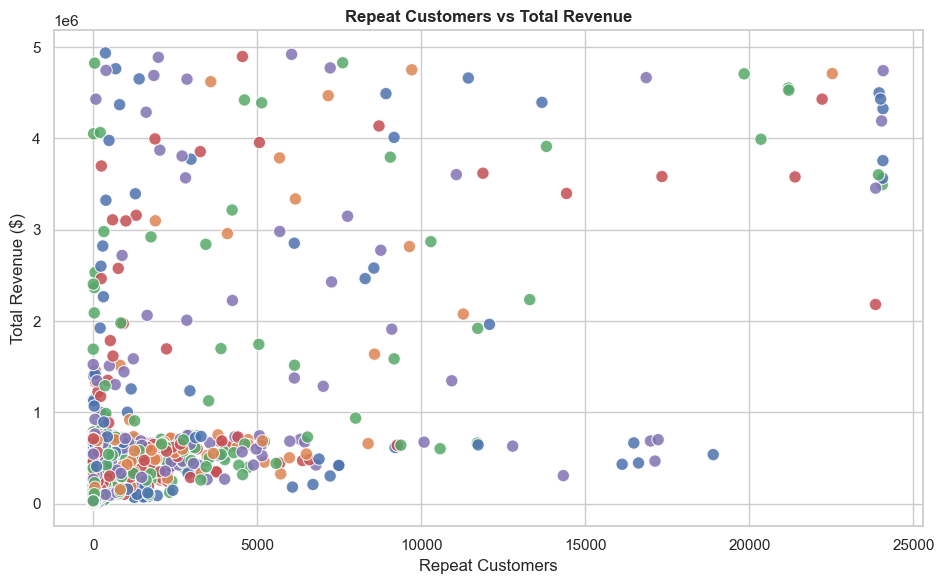

In [15]:
# Plot 1: Repeat Customers Vs Revenue
merchant_scatter(
    merchant_info,
    x="repeat_customers",
    y="sum_total_dollar_value",
    #size_label="customer base",
    hue="segmentation",
    #size="unique_users_all_periods",
    title="Repeat Customers vs Total Revenue",
    savepath="../visualisations/scatter1_repeat_revenue.png",
    x_label= "Repeat Customers",
    y_label= "Total Revenue ($)"
)

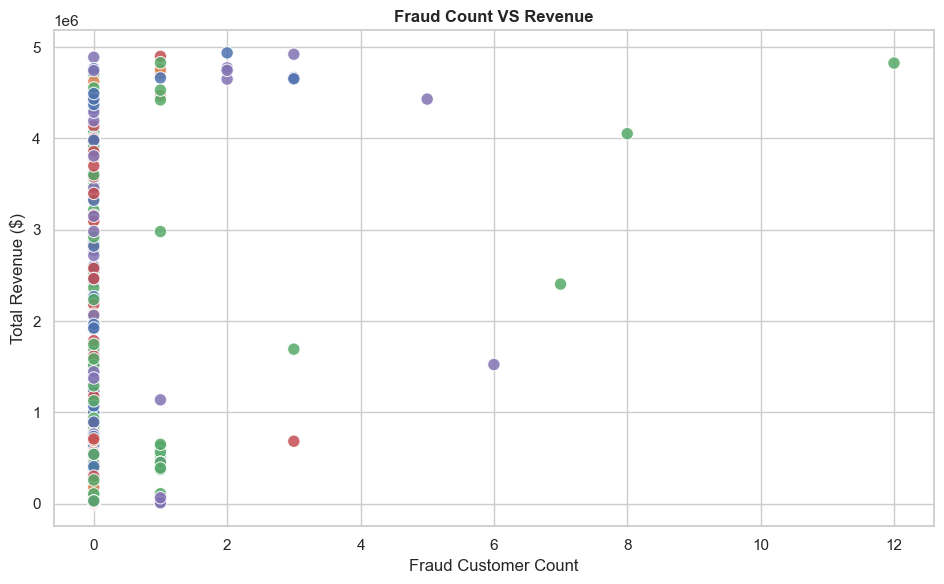

In [16]:
# Plot 2: Fraud Count Vs Total Revenue

merchant_scatter(
    merchant_info,
    x="fraud_count",
    y="sum_total_dollar_value",
    #size_label="customer base",
    #size="unique_users_all_periods",
    x_label= "Fraud Customer Count",
    y_label= "Total Revenue ($)",
    hue="segmentation",
    title="Fraud Count VS Revenue",
    savepath="../visualisations/scatter2_fruad_revenue.png"
)